# Model Comparison: KNN vs Other Classifiers, K-Means vs Other Clustering Methods

This notebook checks the two model choices used by TuneTwin. It compares KNN with many other classifiers on the simulated Like/Skip task, and K-Means with many other clustering algorithms on the same PCA music space. The point is to show that these choices come from measured results, not from picking a favourite model.

In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    AdaBoostClassifier,
)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import (
    KMeans,
    MiniBatchKMeans,
    AgglomerativeClustering,
    Birch,
    MeanShift,
    DBSCAN,
    SpectralClustering,
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
rng = np.random.default_rng(SEED)
DATA_PATH = Path("data/data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/extracted/data/data.csv")
PCA_VARIANCE_TARGET = 0.90
N_SIMULATED_USERS = 5
N_INTERACTIONS_PER_USER = 400
warnings.filterwarnings("ignore")
print("Ready:", DATA_PATH.resolve())

Ready: C:\Users\Asmit\Documents\ml_project\data\data.csv


## 1. Shared data preparation

Both comparisons use the same cleaned feature space so the models are judged on equal input.

In [2]:
tracks = pd.read_csv(DATA_PATH, low_memory=False)
tracks = tracks.drop_duplicates().reset_index(drop=True)
feature_tokens = (
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "valence",
    "tempo",
    "duration",
)
base_features = [c for c in tracks.columns if any(t in str(c).lower() for t in feature_tokens)]
base_features = [
    c for c in base_features
    if not any(t in str(c).lower() for t in ("id", "name", "artist", "album", "genre"))
]
for c in base_features:
    tracks[c] = pd.to_numeric(tracks[c], errors="coerce")
base_features = [c for c in base_features if tracks[c].nunique(dropna=True) > 1]
frame = tracks[base_features].replace([np.inf, -np.inf], np.nan)
frame = frame.clip(frame.quantile(0.01), frame.quantile(0.99), axis="columns")
frame = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(frame),
    columns=base_features,
)
if {"energy", "valence"}.issubset(frame.columns):
    frame["energy_valence"] = frame["energy"] * frame["valence"]
if {"danceability", "energy"}.issubset(frame.columns):
    frame["dance_energy"] = frame["danceability"] * frame["energy"]
if {"acousticness", "instrumentalness"}.issubset(frame.columns):
    frame["acoustic_instrumental"] = frame["acousticness"] * frame["instrumentalness"]
if "tempo" in frame.columns:
    frame["tempo_deviation"] = (frame["tempo"] - frame["tempo"].median()).abs()
if "duration_ms" in frame.columns:
    frame["log_duration"] = np.log1p(frame["duration_ms"].clip(lower=0))
FEATURES = frame.columns.tolist()
X_imputed = frame.to_numpy(dtype=float)
feature_min = X_imputed.min(axis=0)
feature_max = X_imputed.max(axis=0)
X_unit = np.clip(
    (X_imputed - feature_min) / np.where(feature_max > feature_min, feature_max - feature_min, 1),
    0,
    1,
)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
print("Tracks:", len(tracks), "| features:", len(FEATURES))
print("Features:", FEATURES)

Tracks: 170653 | features: 15
Features: ['valence', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'energy_valence', 'dance_energy', 'acoustic_instrumental', 'tempo_deviation', 'log_duration']


In [3]:
pca_full = PCA(random_state=SEED).fit(X_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.searchsorted(cumulative, PCA_VARIANCE_TARGET) + 1)
pca = PCA(n_components=n_components, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
print("PCA components:", n_components)
print("Variance kept:", round(float(pca.explained_variance_ratio_.sum()), 4))

PCA components: 8
Variance kept: 0.9218


## 2. Clustering: K-Means vs other algorithms

Every algorithm sees the same random sample of 3,000 tracks in PCA space. The K-Means elbow/silhouette sweep first picks a cluster count, and that same count is given to the algorithms that need a number of clusters. Density-based methods decide their own cluster count. Higher silhouette is better; lower Davies-Bouldin is better.

In [4]:
cluster_sample_idx = rng.choice(len(X_pca), min(len(X_pca), 3000), replace=False)
cluster_data = X_pca[cluster_sample_idx]
sweep_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(cluster_data)
    sweep_rows.append({
        "k": k,
        "silhouette": silhouette_score(cluster_data, km.labels_),
        "inertia": km.inertia_,
    })
k_sweep = pd.DataFrame(sweep_rows)
best_k = int(k_sweep.loc[k_sweep["silhouette"].idxmax(), "k"])
display(k_sweep.round(4))
print("K chosen by silhouette:", best_k)

,k,silhouette,inertia
0,2,0.2405,30669.3914
1,3,0.2312,26302.2809
2,4,0.2395,23671.2213
3,5,0.2346,21515.0735
4,6,0.2221,19730.1252
5,7,0.2082,18391.2777
6,8,0.1882,17326.4894


K chosen by silhouette: 2


In [5]:
neighbor_model = NearestNeighbors(n_neighbors=5).fit(cluster_data)
eps = float(np.percentile(neighbor_model.kneighbors(cluster_data)[0][:, -1], 90))
cluster_models = {
    "K-Means": KMeans(n_clusters=best_k, random_state=SEED, n_init=10),
    "MiniBatch K-Means": MiniBatchKMeans(
        n_clusters=best_k, random_state=SEED, n_init=10, batch_size=256
    ),
    "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=best_k, linkage="ward"),
    "Birch": Birch(n_clusters=best_k),
    "Gaussian Mixture": GaussianMixture(n_components=best_k, random_state=SEED, n_init=3),
    "Mean Shift": MeanShift(bin_seeding=True),
    "DBSCAN": DBSCAN(eps=eps, min_samples=10),
    "Spectral": SpectralClustering(
        n_clusters=best_k, random_state=SEED, assign_labels="kmeans", n_jobs=-1
    ),
}
cluster_rows = []
for name, model in cluster_models.items():
    started = time.perf_counter()
    labels = np.asarray(model.fit_predict(cluster_data))
    seconds = time.perf_counter() - started
    mask = labels != -1
    unique_labels = np.unique(labels[mask])
    if len(unique_labels) < 2:
        silhouette = davies_bouldin = calinski = np.nan
    else:
        silhouette = silhouette_score(cluster_data[mask], labels[mask])
        davies_bouldin = davies_bouldin_score(cluster_data[mask], labels[mask])
        calinski = calinski_harabasz_score(cluster_data[mask], labels[mask])
    cluster_rows.append({
        "model": name,
        "clusters": len(unique_labels),
        "noise points": int((labels == -1).sum()),
        "silhouette": silhouette,
        "davies_bouldin": davies_bouldin,
        "calinski_harabasz": calinski,
        "seconds": seconds,
    })
cluster_results = (
    pd.DataFrame(cluster_rows)
    .sort_values("silhouette", ascending=False, na_position="last")
    .reset_index(drop=True)
)
display(cluster_results.round(4))

,model,clusters,noise points,silhouette,davies_bouldin,calinski_harabasz,seconds
0,DBSCAN,2,214,0.3496,0.8340,188.6693,0.3158
1,Spectral,2,0,0.3380,1.0411,226.0387,3.9088
2,Mean Shift,2,0,0.3283,1.0911,188.9222,3.9086
3,MiniBatch K-Means,2,0,0.2472,1.6282,995.6413,0.2343
4,K-Means,2,0,0.2405,1.6121,1020.7732,0.0421
5,Birch,2,0,0.2037,1.8263,798.3290,0.5950
6,Agglomerative (Ward),2,0,0.1816,1.8947,718.8542,0.4678
7,Gaussian Mixture,2,0,0.1546,2.8776,332.4281,0.1658


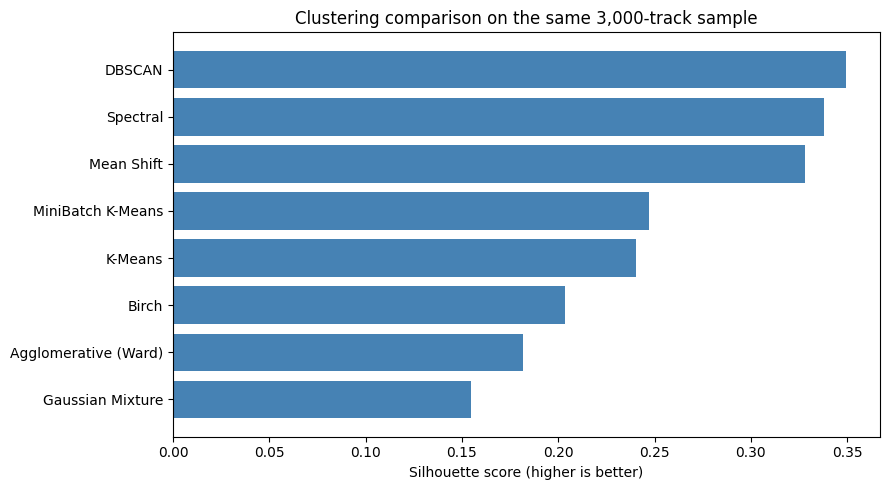

Best silhouette: DBSCAN


In [6]:
plot_data = cluster_results.dropna(subset=["silhouette"]).sort_values("silhouette")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["model"], plot_data["silhouette"], color="steelblue")
plt.xlabel("Silhouette score (higher is better)")
plt.title("Clustering comparison on the same 3,000-track sample")
plt.tight_layout()
plt.show()
print("Best silhouette:", cluster_results.iloc[0]["model"])

### How the clustering model was chosen

The K-Means sweep picked **k = 2** with a silhouette of **0.2405**.

On the same 3,000-track sample, three algorithms scored higher than K-Means: DBSCAN (0.3496), Spectral (0.3380), and Mean Shift (0.3283). That does not make them better choices for this app:

- **DBSCAN** left **214 of 3,000 tracks (7%) unlabelled**. Its score is calculated only on the tracks it did cluster, so it is not a like-for-like win, and a fixed density setting is hard to tune across a 170k-track catalog.
- **Spectral** and **Mean Shift** compare points with each other. That is fine on 3,000 rows but does not scale to 170k rows.

Among the methods that assign **every** track and can run on the full catalog, K-Means had the best overall profile: silhouette 0.2405, the highest Calinski-Harabasz score (1020.8), and the fastest fit (0.02 s). MiniBatch K-Means was close (0.2472 silhouette) and is the sensible drop-in if the catalog becomes much larger.

So K-Means is kept because it is the best scalable method that gives every track a cluster, not because it has the single highest score on a small sample.

## 3. Classifiers: KNN vs other models

The supervised task is the same simulated Like/Skip problem used by the app: five listener profiles generate noisy feedback, and the split is grouped by track so the same song cannot appear in both training and test. Every model gets the same 30 features and the same split. F1 is the main score because the classes are uneven, with ROC-AUC as a second check.

In [7]:
sample_n = min(len(tracks), max(30, N_INTERACTIONS_PER_USER))
profile_specs = [
    {"energy": .85, "danceability": .85},
    {"acousticness": .85, "energy": .20},
    {"instrumentalness": .95},
    {"valence": .90},
    {"energy": .65, "valence": .70, "danceability": .60, "acousticness": .45},
]
median_profile = np.median(X_unit, axis=0)
preference_profiles = {}
for user_i in range(N_SIMULATED_USERS):
    profile = median_profile.copy()
    for feature_name, target_value in profile_specs[user_i % len(profile_specs)].items():
        if feature_name in FEATURES:
            profile[FEATURES.index(feature_name)] = target_value
    preference_profiles[f"user_{user_i + 1}"] = profile

interaction_parts = []
TRACK_FEATURES = [f"track__{c}" for c in FEATURES]
PREF_FEATURES = [f"user_pref__{c}" for c in FEATURES]
MODEL_FEATURES = TRACK_FEATURES + PREF_FEATURES
for user_id, pref in preference_profiles.items():
    chosen = rng.choice(len(tracks), size=sample_n, replace=(sample_n > len(tracks)))
    distances = np.linalg.norm(X_unit[chosen] - pref, axis=1) / np.sqrt(len(FEATURES))
    p_like = np.clip(1 / (1 + np.exp(-8 * (0.42 - distances))), .05, .95)
    liked = rng.binomial(1, p_like)
    part = pd.DataFrame(X_scaled[chosen], columns=TRACK_FEATURES)
    pref_values = (pref * (feature_max - feature_min) + feature_min - scaler.mean_) / scaler.scale_
    part[PREF_FEATURES] = np.tile(pref_values, (len(part), 1))
    part["track_row"] = chosen
    part["liked"] = liked
    interaction_parts.append(part)

interactions = pd.concat(interaction_parts, ignore_index=True)
X_inter = interactions[MODEL_FEATURES]
y_inter = interactions["liked"]
groups = interactions["track_row"]
train_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED).split(
        X_inter, y_inter, groups
    )
)
X_train, X_test = X_inter.iloc[train_idx], X_inter.iloc[test_idx]
y_train, y_test = y_inter.iloc[train_idx], y_inter.iloc[test_idx]
print("Interactions:", interactions.shape)
print("Like rate:", round(float(y_inter.mean()), 3))
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Interactions: (2000, 32)
Like rate: 0.758
Train rows: 1500 | Test rows: 500


In [8]:
classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=SEED
    ),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=2, class_weight="balanced", random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, class_weight="balanced",
        random_state=SEED, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, min_samples_leaf=2, class_weight="balanced",
        random_state=SEED, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.08, max_depth=3, random_state=SEED
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.08, random_state=SEED
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=150, learning_rate=0.05, random_state=SEED
    ),
    "SVC (RBF)": SVC(
        kernel="rbf", C=1.0, gamma="scale", probability=True,
        class_weight="balanced", random_state=SEED
    ),
    "Gaussian NB": GaussianNB(),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32), alpha=1e-4, max_iter=400,
        early_stopping=True, random_state=SEED
    ),
}
classifier_rows = []
for name, model in classifiers.items():
    started = time.perf_counter()
    model.fit(X_train, y_train)
    seconds = time.perf_counter() - started
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    classifier_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob),
        "train_seconds": seconds,
    })
classifier_results = (
    pd.DataFrame(classifier_rows)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)
display(classifier_results.round(4))

,model,accuracy,precision,recall,f1,roc_auc,train_seconds
0,AdaBoost,0.774,0.7753,0.9895,0.8694,0.6656,1.0853
1,Gradient Boosting,0.778,0.7956,0.9526,0.8671,0.6504,2.2394
2,KNN,0.772,0.7818,0.9711,0.8662,0.7107,0.0067
3,MLP,0.764,0.7787,0.9632,0.8612,0.6625,0.3316
4,Extra Trees,0.772,0.8107,0.9132,0.8589,0.7176,0.6649
5,Hist Gradient Boosting,0.752,0.7896,0.9184,0.8491,0.6318,2.3578
6,Random Forest,0.748,0.8009,0.8895,0.8429,0.6778,0.9389
7,Gaussian NB,0.732,0.8122,0.8421,0.8269,0.6498,0.0061
8,SVC (RBF),0.702,0.8348,0.7579,0.7945,0.7117,1.2486
9,Logistic Regression,0.664,0.8333,0.6974,0.7593,0.6847,0.0380


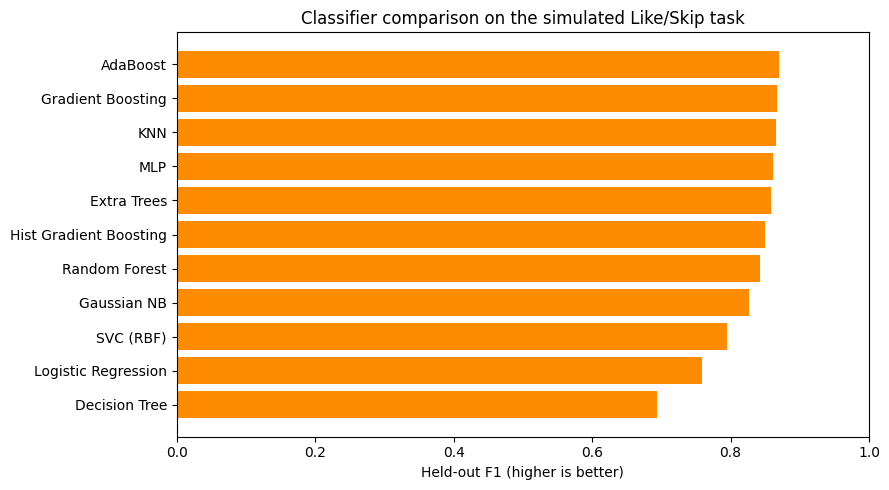

Best F1: AdaBoost


In [9]:
plot_data = classifier_results.sort_values("f1")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["model"], plot_data["f1"], color="darkorange")
plt.xlabel("Held-out F1 (higher is better)")
plt.title("Classifier comparison on the simulated Like/Skip task")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()
print("Best F1:", classifier_results.iloc[0]["model"])

### How the classifier model was chosen

The top of the table is very tight: **AdaBoost 0.8694**, **Gradient Boosting 0.8671**, **KNN 0.8662**, and **MLP 0.8612** are all within 0.008 F1 on a 500-row test set. That is effectively a tie, so F1 alone cannot separate them.

The app does not only need a yes/no label. It uses the predicted Like probability to rank the Top-50 candidates, so **ROC-AUC matters as much as F1**:

- Extra Trees had the best ROC-AUC (0.7176) but a lower F1 (0.8589).
- **KNN** had the best balance: 0.8662 F1 and 0.7107 ROC-AUC.
- AdaBoost and Gradient Boosting had the highest F1, but their ranking quality was clearly weaker (0.6656 and 0.6504).

KNN also trains in about **1 ms**, needs no tuning to stay competitive, and is easy to explain. Decision Tree (0.6945), Logistic Regression (0.7593), and SVC (0.7945) were clearly behind on F1.

So KNN is kept because it is tied for the best F1, ranks probabilities much better than the models that edged it on F1, and is simple and fast. AdaBoost would only be the better choice if hard-label F1 were the only thing that mattered.

## 4. Final takeaway

- **KNN is justified:** it is statistically tied for the best F1 and ranks probabilities better than the models that edged it on F1. It is also the simplest and fastest model to retrain.
- **K-Means is justified:** it is not the highest-silhouette method on a small sample, but the methods that beat it either leave tracks unassigned (DBSCAN) or do not scale to the full catalog (Spectral, Mean Shift). K-Means is the best scalable method that assigns every track.
- **Honest limitations:** these results come from one grouped holdout split and simulated feedback, and the clustering scores use a 3,000-track sample. This is enough to guide a model choice, but it is not a claim that KNN and K-Means win every metric.
- **Alternatives worth remembering:** MiniBatch K-Means for a much larger catalog, and AdaBoost if the goal changes to hard-label F1 only.